<a href="https://colab.research.google.com/github/leejsya/BreastMNIST/blob/main/BreastMNIST_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### 데이터 준비

In [ ]:
seed = 42

import numpy as np
import torch
import matplotlib.pyplot as plt

# npz 데이터 로드
data = np.load("breastmnist.npz")

# 시드 고정
torch.manual_seed(seed)

In [ ]:
# npz 파일 key 확인
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


In [ ]:
data_dict = dict(data)

for split in ['train', 'val', 'test']:
    data_dict[f"{split}_labels"] = 1 - data_dict[f"{split}_labels"]

In [ ]:
# train_images/labels의 shape 확인
imgs = data_dict['train_images']
labels = data_dict['train_labels']
print(f"images(개수, 높이, 너비): {imgs.shape}")
print(f"labels(개수, 라벨): {labels.shape}")

images(개수, 높이, 너비): (546, 224, 224)
labels(개수, 라벨): (546, 1)


#### 샘플 이미지 확인

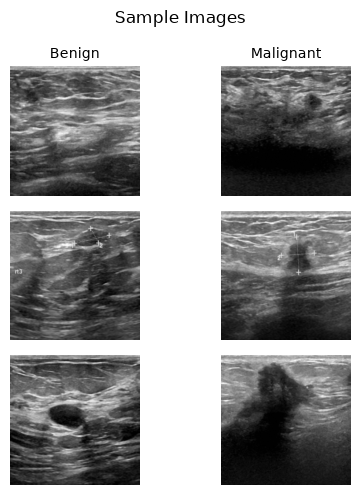

In [ ]:
# 라벨이 0인 데이터들의 인덱스 목록
idx_0 = np.where(labels==0)[0]
# 라벨이 1인 데이터들의 인덱스 목록
idx_1 = np.where(labels==1)[0]

fig, axes = plt.subplots(3, 2, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    if i % 2 == 0:
        ax.imshow(imgs[idx_0][i], cmap='gray')
        ax.axis('off')
        if i == 0:
            ax.set_title("Benign", fontsize=10)
    else:
        ax.imshow(imgs[idx_1][i], cmap='gray')
        ax.axis('off')
        if i == 1:
            ax.set_title("Malignant", fontsize=10)
plt.suptitle("Sample Images")
plt.tight_layout()
plt.show()

#### 샘플 수 & 분포 확인

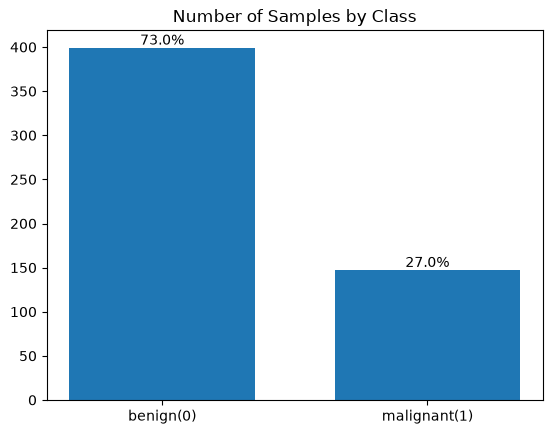

In [ ]:
# 라벨별 샘플 수 확인
bar1 = plt.bar(['benign(0)', 'malignant(1)'], [len(idx_0), len(idx_1)], width=0.7)
ratio_0 = round(len(idx_0)/(len(idx_0)+len(idx_1)), 2)
ratio_1 = 1 - ratio_0
plt.bar_label(
    bar1,
    labels=[f"{ratio_0*100}%", f"{ratio_1*100}%"]
)
plt.title("Number of Samples by Class")
plt.show()

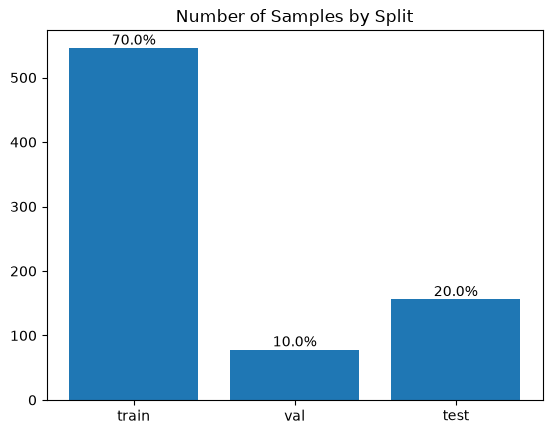

In [ ]:
# train/val/test별 샘플 수 확인
n_train = len(data_dict['train_images'])
n_val = len(data_dict['val_images'])
n_test = len(data_dict['test_images'])
ratio_train = round(n_train / (n_train + n_val + n_test), 3)
ratio_val = round(n_val / (n_train + n_val + n_test), 3)
ratio_test = round(1 - ratio_train - ratio_val, 3)

bar2 = plt.bar(['train','val', 'test'], [n_train, n_val, n_test])
plt.bar_label(
    bar2,
    labels=[f"{ratio_train*100}%", f"{ratio_val*100}%", f"{ratio_test*100}%"]
)
plt.title("Number of Samples by Split")
plt.show()

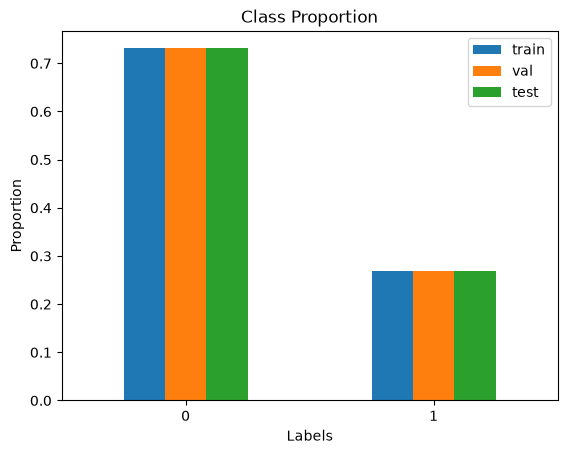

In [ ]:
# train/val/test 클래스 비율 확인
import pandas as pd

labels_dict = {
    'train_labels' : data_dict['train_labels'],
    'val_labels' : data_dict['val_labels'],
    'test_labels' : data_dict['test_labels']
}
prop_dict = {}
for split in ['train', 'val', 'test']:
    uniques, counts = np.unique(labels_dict[f"{split}_labels"], return_counts=True)
    prop_dict[split] = counts/counts.sum()

prop_df = pd.DataFrame(prop_dict)
prop_df.plot.bar(rot=0)
plt.xlabel("Labels")
plt.ylabel("Proportion")
plt.title("Class Proportion")
plt.show()

#### Pre-trained 모델 정보 가져오기

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

# pre-trained 모델의 파라미터 가져오기
weights = ResNet18_Weights.IMAGENET1K_V1
# pre-trained 모델 가져오기
model = resnet18(weights=weights)
# pre-trained 모델의 transform 가져오기
model_transform = weights.transforms()

In [ ]:
# 모델 구조 확인
from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 224, 224),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        True
├─Conv2d (conv1)                         9,408                     True
├─BatchNorm2d (bn1)                      128                       True
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        True
│    └─BasicBlock (0)                    73,984                    True
│    └─BasicBlock (1)                    73,984                    True
├─Sequential (layer2)                    --                        True
│    └─BasicBlock (0)                    230,144                   True
│    └─BasicBlock (1)                    295,424                   True
├─Sequential (layer3)                    --                        True
│    └─BasicBlock (0)                    919,040               

In [ ]:
import torch.nn as nn
# Backbone 전체 고정
for p in model.parameters():
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 1)

# Backbone 고정 및 FC Layer 교체 후 모델 구조 다시 확인
summary(
    model,
    input_size=(1, 3, 224, 224),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        Partial
├─Conv2d (conv1)                         (9,408)                   False
├─BatchNorm2d (bn1)                      (128)                     False
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        False
│    └─BasicBlock (0)                    (73,984)                  False
│    └─BasicBlock (1)                    (73,984)                  False
├─Sequential (layer2)                    --                        False
│    └─BasicBlock (0)                    (230,144)                 False
│    └─BasicBlock (1)                    (295,424)                 False
├─Sequential (layer3)                    --                        False
│    └─BasicBlock (0)                    (919,040) 

In [ ]:
# device 설정
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model.to(device)
print(device)

mps


In [ ]:
# model_transform 확인
print(model_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:
# model_transform 내부코드 확인
import inspect
print(inspect.getsource(type(model_transform).forward))

    def forward(self, img: Tensor) -> Tensor:
        img = F.resize(img, self.resize_size, interpolation=self.interpolation, antialias=self.antialias)
        img = F.center_crop(img, self.crop_size)
        if not isinstance(img, Tensor):
            img = F.pil_to_tensor(img)
        img = F.convert_image_dtype(img, torch.float)
        img = F.normalize(img, mean=self.mean, std=self.std)
        return img



In [ ]:
# model_transform의 mean과 std값만 사용
base_mean = model_transform.mean
base_std = model_transform.std

print(base_mean)
print(base_std)

[0.485, 0.456, 0.406]
[0.229, 0.224, 0.225]


#### Transforms

In [ ]:
from torchvision.transforms import v2

train_transform = v2.Compose(
    [
        v2.ToImage(),
        # 3채널로 확장
        v2.Grayscale(num_output_channels=3),
        v2.RandomHorizontalFlip(),
        v2.RandomResizedCrop(size=224, scale=(0.8, 1.0)),
        v2.RandomRotation(degrees=10),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # pre-trained 모델을 기준으로 normalize
        v2.Normalize(mean=base_mean, std=base_std)
    ]
)

eval_transform = v2.Compose(
    [
        v2.ToImage(),
        # 3채널로 확장
        v2.Grayscale(num_output_channels=3),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # pre-trained 모델을 기준으로 normalize
        v2.Normalize(mean=base_mean, std=base_std)
    ]
)


#### Dataset

In [ ]:
from torch.utils.data import Dataset

class BMNISTDataset(Dataset):
    def __init__(self, split, transform):
        self.images = data_dict[f"{split}_images"]
        self.labels = data_dict[f"{split}_labels"]
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # image는 transform을 적용시키면 자동으로 텐서로 변환됨.
        image_tensor = self.transform(self.images[idx])
        label_tensor = torch.tensor(self.labels[idx], dtype=torch.float32)

        return image_tensor, label_tensor

In [ ]:
train_dataset = BMNISTDataset(
    split="train",
    transform=train_transform
)
val_dataset = BMNISTDataset(
    split="val",
    transform=eval_transform
)
test_dataset = BMNISTDataset(
    split="test",
    transform=eval_transform
)

#### DataLoader

In [ ]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=16,
    shuffle=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=26,

)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=32
)

#### Training Loop

In [ ]:
# Evaluation Function
def evaluate(dataloader, model, loss_fn):
    model.eval()
    losses = []
    correct, total = 0, 0
    all_preds = []
    all_probs = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            logits = model(inputs)

            loss = loss_fn(logits, labels)
            losses.append(loss.item())

            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).long()
            correct += (preds == labels).sum().item()
            total += len(logits)
            all_preds.extend(preds.cpu())
            all_probs.extend(probs.cpu())

        acc = correct / total
        avg_loss = sum(losses) / len(losses)
    return avg_loss, acc, all_preds, all_probs


In [ ]:
def Train_Loop(dataloader, model, optimizer, epochs, min_loss, history_dict):
    for epoch in range(epochs):
        losses = []
        correct, total = 0, 0
        model.train()
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d): # and not m.weight.requires_grad:
                m.eval()

        for train_batch in dataloader:
            inputs, labels = train_batch[0].to(device), train_batch[1].to(device)
            logits = model(inputs)

            # 파라미터 업데이트
            loss = loss_fn(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # loss, correct, total 결과 저장
            losses.append(loss.item())
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).long()
            correct += (preds == labels).sum().item()
            total += len(logits)

        train_loss = sum(losses) / len(losses)
        train_acc = correct / total

        history_dict["train_loss"].append(train_loss)
        history_dict["train_acc"].append(train_acc)

        # Validation
        val_loss, val_acc, _, _ = evaluate(val_dataloader, model, loss_fn)
        history_dict["val_loss"].append(val_loss)
        history_dict["val_acc"].append(val_acc)

        # loss값이 최소일 때 상태를 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'model.pt')

    return min_loss, history_dict

#### Stage 1(FC Layer)

In [ ]:
import torch.optim as optim

min_loss = float('inf')

history_dict = {
    "train_loss" : [],
    "train_acc" : [],
    "val_loss" : [],
    "val_acc" : [],
}

''' loss function '''
# idx_1 : 라벨이 1인 이미지의 인덱스 리스트
# 전체 샘플 중 라벨이 1인 샘플의 비율의 역수를 가중치로 설정
weight_value = len(labels) / len(idx_1)
# 클래스 1에 가중치 부여
pos_weight = torch.tensor([weight_value], device=device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# 1단계 학습을 위한 optimizer
optimizer1 = optim.Adam(model.fc.parameters(), lr=1e-3)

# 1단계 학습 진행
min_loss, history_dict = Train_Loop(
    dataloader=train_dataloader,
    model=model,
    optimizer=optimizer1,
    epochs=15,
    min_loss=min_loss,
    history_dict=history_dict
)

In [ ]:
len(labels) / len(idx_1)

3.7142857142857144

#### Stage 2(Layer4 + FC Layer)

In [ ]:
for p in model.layer4.parameters():
    p.requires_grad = True

summ = summary(
    model,
    input_size=(1, 3, 224, 224),
    # 파라미터 개수, trainable 여부 표시
    col_names=['num_params', 'trainable'],
    # layer의 변수명 표시
    row_settings=['var_names'],
    # 블록 단위로만 표시
    depth=2,
)

# summary를 호출했을 때 모델이 CUDA에 있는 게 아니라면 강제로 모델이 CPU로 옮겨감.
model.to(device)
print(summ)

Layer (type (var_name))                  Param #                   Trainable
ResNet (ResNet)                          --                        Partial
├─Conv2d (conv1)                         (9,408)                   False
├─BatchNorm2d (bn1)                      (128)                     False
├─ReLU (relu)                            --                        --
├─MaxPool2d (maxpool)                    --                        --
├─Sequential (layer1)                    --                        False
│    └─BasicBlock (0)                    (73,984)                  False
│    └─BasicBlock (1)                    (73,984)                  False
├─Sequential (layer2)                    --                        False
│    └─BasicBlock (0)                    (230,144)                 False
│    └─BasicBlock (1)                    (295,424)                 False
├─Sequential (layer3)                    --                        False
│    └─BasicBlock (0)                    (919,040) 

In [ ]:
# 2단계 학습을 위한 optimizer
optimizer2 = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])

# 2단계 학습을 진행하기 전, 모델을 성능이 가장 좋았던 모델로 로드
model.load_state_dict(torch.load('model.pt', map_location=device))

# 2단계 학습 진행
min_loss, history_dict = Train_Loop(
    dataloader=train_dataloader,
    model=model,
    optimizer=optimizer2,
    epochs=35,
    min_loss=min_loss,
    history_dict=history_dict
)

#### Test

In [ ]:
model.load_state_dict(torch.load('model.pt', map_location=device))
test_loss, test_acc, all_preds, all_probs = evaluate(test_dataloader, model, loss_fn)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")

test loss: 0.7308, test acc: 0.9103


In [ ]:
def EMA(history, alpha):
    ema_list = []
    for i, loss in enumerate(history):
        if i == 0:
            ema_loss = loss
        else:
            ema_loss = alpha * loss + (1 - alpha) * ema_loss
        ema_list.append(ema_loss)
    return ema_list

train_loss_ema = EMA(history_dict['train_loss'], alpha=0.3)
train_acc_ema = EMA(history_dict['train_acc'], alpha=0.3)
val_loss_ema = EMA(history_dict['val_loss'], alpha=0.3)
val_acc_ema = EMA(history_dict['val_acc'], alpha=0.3)

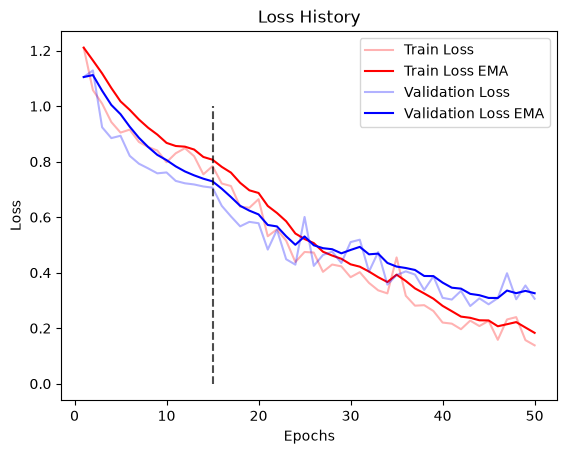

In [ ]:
total_epochs = len(history_dict['train_loss'])

plt.plot(range(1, total_epochs+1), history_dict['train_loss'], 'r', label="Train Loss", alpha=0.3)
plt.plot(range(1, total_epochs+1), train_loss_ema, 'r', label="Train Loss EMA")
plt.plot(range(1, total_epochs+1), history_dict['val_loss'], 'b', label="Validation Loss", alpha=0.3)
plt.plot(range(1, total_epochs+1), val_loss_ema, 'b', label="Validation Loss EMA")
plt.plot([15, 15], [0, 1], 'k--', alpha=0.7)
plt.title("Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

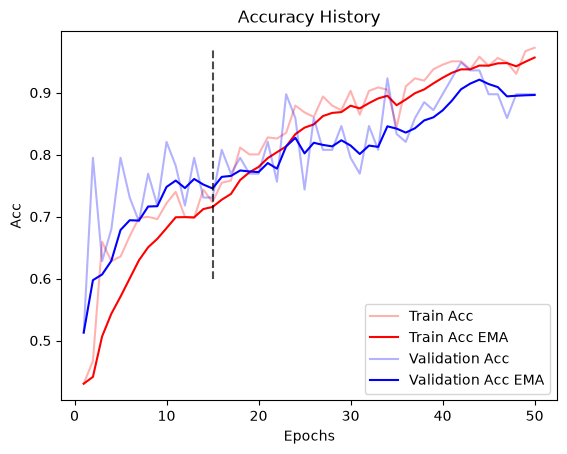

In [ ]:
plt.plot(range(1, len(history_dict['train_acc'])+1), history_dict['train_acc'], 'r', label='Train Acc', alpha=0.3)
plt.plot(range(1, total_epochs+1), train_acc_ema, 'r', label="Train Acc EMA")
plt.plot(range(1, len(history_dict['val_acc'])+1), history_dict['val_acc'], 'b', label='Validation Acc', alpha=0.3)
plt.plot(range(1, total_epochs+1), val_acc_ema, 'b', label="Validation Acc EMA")
plt.plot([15, 15], [0.60, 0.97], 'k--', alpha=0.7)
plt.title("Accuracy History")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(data_dict['test_labels'], all_preds, output_dict=True)
print(classification_report(data_dict['test_labels'], all_preds))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94       114
           1       0.85      0.81      0.83        42

    accuracy                           0.91       156
   macro avg       0.89      0.88      0.88       156
weighted avg       0.91      0.91      0.91       156



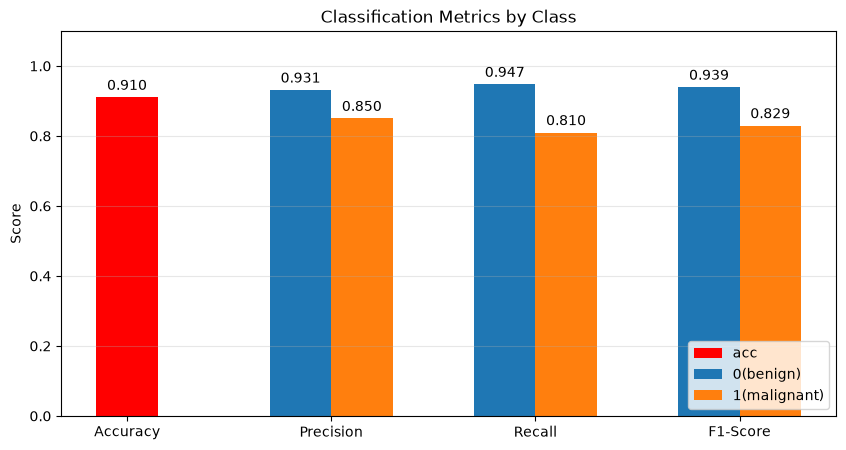

In [ ]:
classes = ['0', '1']
metrics = ['precision', 'recall', 'f1-score']
accuracy = report['accuracy']

x = np.arange(len(metrics)) + 1
width = 0.3

fig, ax = plt.subplots(figsize=(10,5))

acc_bar = ax.bar(0, accuracy, width, color='r', label='accuracy')
ax.bar_label(acc_bar, fmt='%.3f', padding=3)

for i, cls in enumerate(classes):
    values = [report[cls][m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=cls)
    ax.bar_label(bars, fmt='%.3f', padding=3)

ax.set_xticks(np.arange(len(metrics) + 1), ['Accuracy', 'Precision', 'Recall', 'F1-Score'])
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.set_title('Classification Metrics by Class')
ax.legend(['acc','0(benign)','1(malignant)'], loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.show()

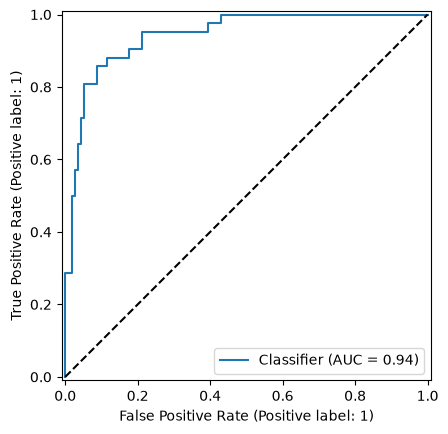

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(data_dict['test_labels'], all_probs)
plt.plot([0,1], [0,1], "k--")
plt.show()

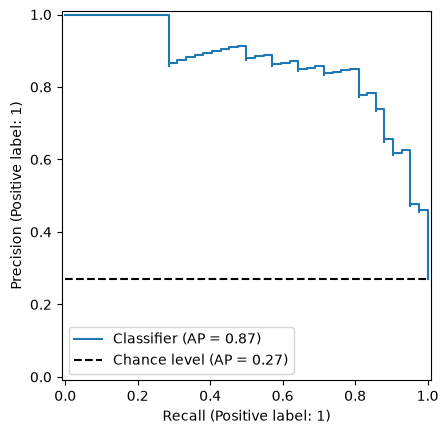

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay as PRCurve
PRCurve.from_predictions(data_dict['test_labels'], all_probs, plot_chance_level=True)
plt.show()

In [ ]:
# # eval 모드로 변경
# model.eval()
# # 입력데이터 예시
# example = torch.randn(1, 3, 224, 224).cpu()
# # 모델 export
# ep_model = torch.export.export(model.cpu(), (example,))
# # export한 모델을 파일로 저장
# torch.export.save(ep_model, "ep_model.pt2")

In [ ]:
# loaded = torch.export.load("ep_model.pt2").module()

# x = torch.randn(1, 3, 224, 224)

# # gradient를 계산하지 않는 추론모드(torch.no_grad()보다 가벼움)
# with torch.inference_mode():
#     # 두 모델에 텐서를 입력했을 때 두 텐서의 모든 값이 같으면 True를 반환함.
#     print(torch.allclose(loaded(x), model(x), atol=1e-5))